> **v2.3 reference derivative — computer-generated working, not handwritten traces.**
> Copy of `EmiratesPost_Graphs_and_Working.ipynb` (kept unchanged beside this file). Changes in the Network Audit v2.3
> refinement: the stale "dashboard (v2.1)" wording is refreshed; section 6 now recomputes the dashboard side from the
> project's own v2.3 code and *computes* MATCH / MISMATCH instead of comparing with a typed copy; a short service-
> disposition cell is added. All other cells, tables and the 11 figures are the original outputs (figures byte-identical,
> verified by `tools/make_notebook_v2_3_reference.py`). These outputs accompany each member's separate handwritten trace;
> they do not replace it.

# Emirates Post Network Audit: graphs and working
**Design and Analysis of Algorithms · MAIB · Final project**

Every figure and table the *Our working* tab needs, computed from the same data as the dashboard (input data unchanged since v2.1; compared with the v2.3 build in section 6):
Kushal's 21 Google Maps times (Thu 5 Nov 2026, 07:00), threshold **X = 38**, hub **HUB (Al Ramool)**,
proposed internal transfer target **20 min**, budget **AED 450,000**, Joan's four priced upgrades.

| Section | Algorithm | Owner |
|---|---|---|
| 1 | Data and threshold X | Kushal (Data Lead) |
| 2 | DFS connectivity check | Kushal (Data Lead) |
| 3 | Kruskal minimum network | Shashaank (Network Analyst) |
| 4 | Dijkstra service coverage | Siddal (Routing Analyst) |
| 5 | 0/1 knapsack (dynamic programming) vs greedy | Joan (Investment Analyst) |
| 6 | Summary: notebook vs dashboard | Sparsh Saraya (Integration & Business Lead) |

These are the **computer outputs** to place *beside* each member's handwritten trace. They are not the hand-traces themselves.

Run top to bottom (`Kernel → Restart & Run All`). Needs `pandas`, `networkx`, `matplotlib`.

In [1]:
import math, itertools
from pathlib import Path
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle

pd.set_option("display.width", 200); pd.set_option("display.max_colwidth", 80)
plt.rcParams.update({"figure.dpi": 110, "font.size": 10, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.titleweight": "bold", "axes.titlesize": 12})
GREEN, RED, BLUE, GREY, AMBER, NAVY = "#2E7D32", "#C62828", "#1565C0", "#9E9E9E", "#E69F00", "#1B2A41"

# ---- Baseline scenario (same as the dashboard)
X, HUB, TARGET, BUDGET = 38, "HUB", 20, 450_000
ORDER = ["HUB", "KAR", "QUS", "UMS", "JAF", "SHJ", "AJM"]          # matrix order used in every hand trace

# ---- Data: read the dashboard's CSVs if this notebook sits in the project; otherwise use the embedded copy
def find_data():
    for d in [Path("data"), Path("../data"), Path("network-audit/data")]:
        if (d / "times.csv").exists() and (d / "branches.csv").exists() and (d / "upgrades.csv").exists():
            return d
    return None

EMBED_TIMES = [("HUB","KAR",13),("HUB","QUS",16),("HUB","UMS",23),("HUB","JAF",38),("HUB","SHJ",24),("HUB","AJM",38),
               ("KAR","QUS",25),("KAR","UMS",20),("KAR","JAF",34),("KAR","SHJ",30),("KAR","AJM",48),("QUS","UMS",32),
               ("QUS","JAF",48),("QUS","SHJ",29),("QUS","AJM",37),("UMS","JAF",24),("UMS","SHJ",40),("UMS","AJM",55),
               ("JAF","SHJ",53),("JAF","AJM",65),("SHJ","AJM",27)]
EMBED_BRANCHES = [("HUB","Al Ramool (hub)","Umm Ramool / Al Garhoud",25.2361508,55.3580611),
                  ("KAR","Dubai Central","Al Karama",25.2446884,55.3092365),
                  ("QUS","Al Qusais","Al Twar 5 / Al Qusais",25.2652187,55.3896729),
                  ("UMS","Umm Suqeim","Umm Suqeim 2",25.1449609,55.2036356),
                  ("JAF","JAFZA","Jebel Ali Free Zone",24.9881858,55.0880852),
                  ("SHJ","Sharjah Central","Al Soor",25.3519346,55.3902551),
                  ("AJM","Ajman Central","Al Bustan",25.4088241,55.4450538)]
EMBED_UPGRADES = [("UMS","Express motorbike courier",69900,135000),("JAF","JAFZA mini-hub",143520,360000),
                  ("SHJ","Sharjah mini-hub",130920,225000),("AJM","Ajman mini-hub",137520,180000)]

d = find_data()
if d is not None:
    times = pd.read_csv(d / "times.csv")
    br = pd.read_csv(d / "branches.csv")
    branches = pd.DataFrame({"Code": br["Code"], "Area": br["Area"], "Lat": br["Latitude"], "Lon": br["Longitude"]})
    upgrades = pd.read_csv(d / "upgrades.csv")[["Code", "Upgrade", "Cost_AED", "Benefit_AED"]]
    print(f"Loaded the dashboard's data files from {d.as_posix()}/")
else:
    times = pd.DataFrame(EMBED_TIMES, columns=["From", "To", "Minutes"])
    branches = pd.DataFrame([(c, a, la, lo) for c, _, a, la, lo in EMBED_BRANCHES], columns=["Code", "Area", "Lat", "Lon"])
    upgrades = pd.DataFrame(EMBED_UPGRADES, columns=["Code", "Upgrade", "Cost_AED", "Benefit_AED"])
    print("Using the embedded copy of the dashboard's data (v2.1)")

AREA = dict(zip(branches["Code"], branches["Area"]))
T = {frozenset((a, b)): int(m) for a, b, m in times[["From", "To", "Minutes"]].itertuples(index=False)}
assert len(T) == 21, "expected 21 pairs"
print(f"21 pairs, {times.Minutes.min()}–{times.Minutes.max()} min · X = {X} · hub {HUB} · target {TARGET} min · budget AED {BUDGET:,}")

Loaded the dashboard's data files from ../data/
21 pairs, 13–65 min · X = 38 · hub HUB · target 20 min · budget AED 450,000


In [2]:
# ---- Shared helpers: routes under X, graph, positions, a drawing function used by every network figure
def routes_under(x):
    r = [(a, b, m) for (a, b, m) in times[["From", "To", "Minutes"]].itertuples(index=False) if m < x]   # strict rule
    return sorted(r, key=lambda e: (e[2], ORDER.index(e[0]), ORDER.index(e[1])))

def graph(edges):
    G = nx.Graph(); G.add_nodes_from(ORDER); G.add_weighted_edges_from(edges); return G

ROUTES = routes_under(X)
G = graph(ROUTES)

# Schematic positions (same layout as the Data Lead's diagram): real west–east / south–north order, not to scale.
# The true geography squeezes HUB, KAR and QUS into a few km, so a schematic keeps every label readable.
POS = {"HUB": (4.6, -3.1), "KAR": (3.8, -4.6), "QUS": (3.7, -2.5), "UMS": (2.4, -4.0),
       "JAF": (1.8, -5.7), "SHJ": (6.0, -2.3), "AJM": (7.1, -1.25)}
LABEL_SIDE = {"HUB": (1, -0.6), "KAR": (1, -1), "QUS": (-1, 1), "UMS": (-1, 0), "JAF": (-1, -0.6), "SHJ": (1, -0.8), "AJM": (1, 0.6)}

def key(a, b): return frozenset((a, b))

def draw_network(ax, title, edge_style=None, node_colour=None, node_text=None, base_edges=ROUTES, show_minutes=True, legend=None):
    """edge_style: {frozenset(a,b): dict(color, lw, ls, alpha)}; anything not listed is drawn thin grey."""
    edge_style = edge_style or {}
    for a, b, m in base_edges:
        s = dict(color=GREY, lw=1.2, ls="-", alpha=0.55); s.update(edge_style.get(key(a, b), {}))
        (x1, y1), (x2, y2) = POS[a], POS[b]
        ax.plot([x1, x2], [y1, y2], color=s["color"], lw=s["lw"], ls=s["ls"], alpha=s["alpha"], zorder=1)
        if show_minutes:
            bold = key(a, b) in edge_style and edge_style[key(a, b)].get("lw", 1) > 2
            ax.text((x1 + x2) / 2, (y1 + y2) / 2, str(m), fontsize=8.5, ha="center", va="center", zorder=3,
                    fontweight="bold" if bold else "normal", color=s["color"] if bold else "#555",
                    bbox=dict(boxstyle="round,pad=0.15", fc="white", ec="none", alpha=0.85))
    for c in ORDER:
        x, y = POS[c]
        ax.scatter([x], [y], s=260, color=(node_colour or {}).get(c, "white"), edgecolor=NAVY, lw=1.6, zorder=4)
        sx, sy = LABEL_SIDE[c]
        txt = (node_text or {}).get(c, f"{c} · {AREA[c]}")
        ax.annotate(txt, (x, y), xytext=(15 * sx, 12 * sy), textcoords="offset points", fontsize=9,
                    ha="left" if sx > 0 else "right", va="center", zorder=5)
    ax.set_aspect("equal"); ax.set_title(title, loc="left"); ax.axis("off")
    if legend:
        from matplotlib.lines import Line2D
        ax.legend(handles=[Line2D([0], [0], color=c, lw=w, ls=l) for _, c, l, w in legend],
                  labels=[t for t, *_ in legend], frameon=False, loc="upper left", fontsize=9)
    ax.text(0, -0.02, "Schematic layout: real west–east / south–north order, not to scale. "
            "Numbers on lines = Google Maps drive minutes (Thu 07:00).", transform=ax.transAxes, fontsize=8, color="#666")
    xs = [p[0] for p in POS.values()]; ys = [p[1] for p in POS.values()]
    ax.set_xlim(min(xs) - 1.6, max(xs) + 1.9); ax.set_ylim(min(ys) - 0.5, max(ys) + 0.4)

print(f"Routes under X = {X}: {len(ROUTES)}")

Routes under X = 38: 13


## 1 · Data and threshold X (Kushal, Data Lead)
A direct van route exists only if its Google Maps drive time is **strictly under X**. X = 38 gives 13 routes (inside the brief's 10–14), keeps every branch connected, and is the smallest X that lets in Qusais–Ajman (37 min), so Ajman no longer hangs on Sharjah alone.

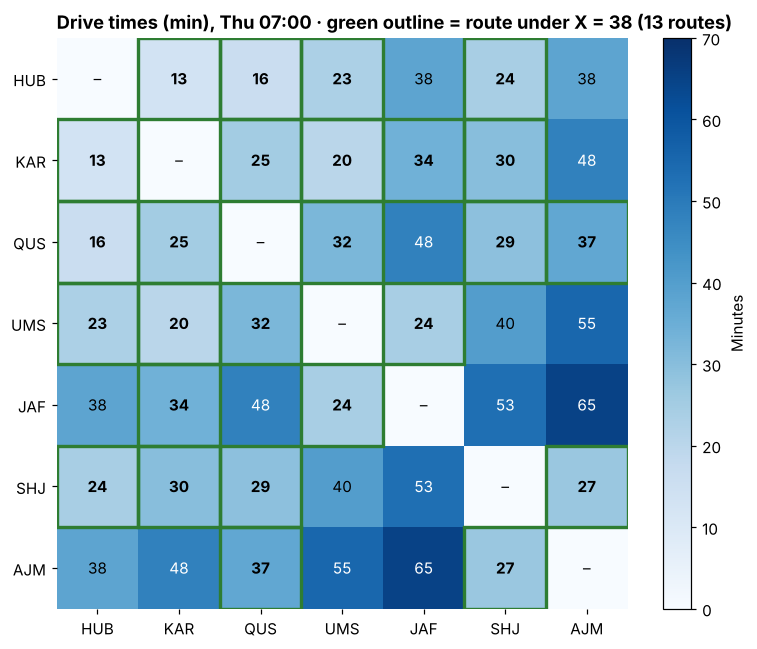

In [3]:
# Figure 1.1: the 21 drive times as a 7×7 matrix; outlined cells = routes under X
M = pd.DataFrame(0, index=ORDER, columns=ORDER)
for (a, b), m in [(tuple(k), v) for k, v in T.items()]:
    M.loc[a, b] = M.loc[b, a] = m
fig, ax = plt.subplots(figsize=(7.2, 6))
im = ax.imshow(M.values, cmap="Blues", vmin=0, vmax=70)
for i, a in enumerate(ORDER):
    for j, b in enumerate(ORDER):
        v = M.iloc[i, j]
        ax.text(j, i, "–" if i == j else v, ha="center", va="center", fontsize=10,
                color="white" if v > 45 else "black", fontweight="bold" if (i != j and v < X) else "normal")
        if i != j and v < X:
            ax.add_patch(Rectangle((j - .5, i - .5), 1, 1, fill=False, ec=GREEN, lw=2.2))
ax.set_xticks(range(7), ORDER); ax.set_yticks(range(7), ORDER)
ax.set_title(f"Drive times (min), Thu 07:00 · green outline = route under X = {X} (13 routes)", loc="left")
plt.colorbar(im, ax=ax, fraction=0.046, label="Minutes"); ax.spines[:].set_visible(False)
plt.tight_layout(); plt.show()

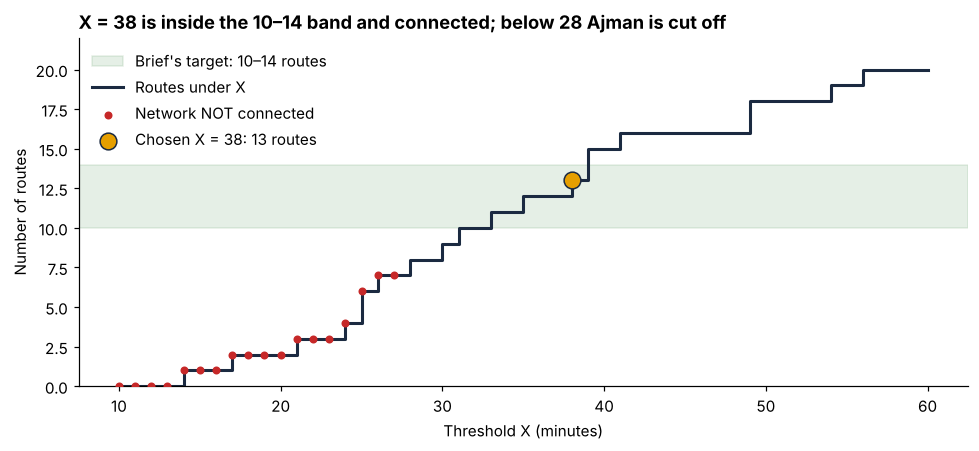

,Routes,Connected,Cut off
X,,,
26,7,False,AJM
27,7,False,AJM
28,8,True,–
29,8,True,–
30,9,True,–
31,10,True,–
32,10,True,–
33,11,True,–
34,11,True,–


In [4]:
# Figure 1.2: how many routes survive at each X, and is the network connected?
rows = []
for x in range(10, 61):
    g = graph(routes_under(x))
    rows.append({"X": x, "Routes": g.number_of_edges(), "Connected": nx.is_connected(g),
                 "Cut off": ", ".join(sorted(set(ORDER) - nx.node_connected_component(g, HUB))) or "–"})
TH = pd.DataFrame(rows)
fig, ax = plt.subplots(figsize=(9, 4.2))
ax.axhspan(10, 14, color=GREEN, alpha=0.12, label="Brief's target: 10–14 routes")
ax.step(TH.X, TH.Routes, where="post", color=NAVY, lw=2, label="Routes under X")
dis = TH[~TH.Connected]
ax.scatter(dis.X, dis.Routes, color=RED, s=18, zorder=3, label="Network NOT connected")
ax.scatter([X], [TH.loc[TH.X == X, "Routes"].item()], s=120, color=AMBER, edgecolor=NAVY, zorder=4, label=f"Chosen X = {X}: 13 routes")
ax.set_xlabel("Threshold X (minutes)"); ax.set_ylabel("Number of routes"); ax.set_ylim(0, 22)
ax.set_title("X = 38 is inside the 10–14 band and connected; below 28 Ajman is cut off", loc="left")
ax.legend(frameon=False, loc="upper left"); plt.tight_layout(); plt.show()
TH[(TH.X >= 26) & (TH.X <= 40)].set_index("X")

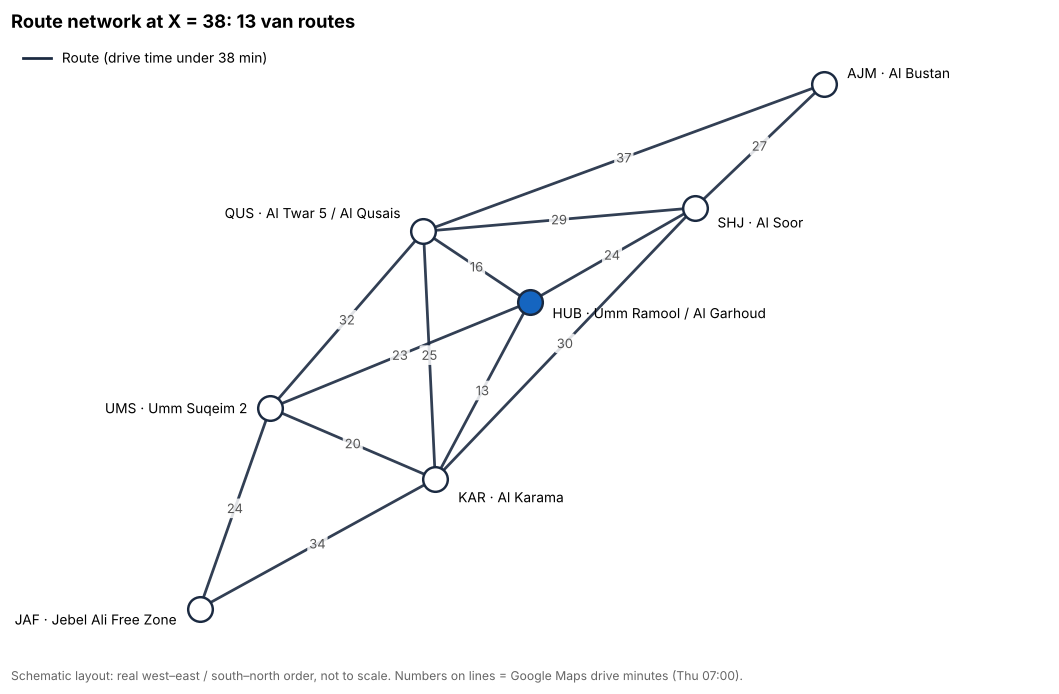

,From,To,Minutes
0,HUB,KAR,13
1,HUB,QUS,16
2,KAR,UMS,20
3,HUB,UMS,23
4,HUB,SHJ,24
5,UMS,JAF,24
6,KAR,QUS,25
7,SHJ,AJM,27
8,QUS,SHJ,29
9,KAR,SHJ,30


In [5]:
# Figure 1.3: the route network at X = 38
fig, ax = plt.subplots(figsize=(10, 7))
draw_network(ax, f"Route network at X = {X}: 13 van routes", node_colour={HUB: BLUE},
             edge_style={key(a, b): dict(color=NAVY, lw=1.8, alpha=0.9) for a, b, _ in ROUTES},
             legend=[(f"Route (drive time under {X} min)", NAVY, "-", 1.8)])
plt.tight_layout(); plt.show()
pd.DataFrame(ROUTES, columns=["From", "To", "Minutes"])

## 2 · DFS connectivity check (Kushal, Data Lead)
Depth-first search from HUB, checking neighbours in matrix order (HUB, KAR, QUS, UMS, JAF, SHJ, AJM). If all 7 branches are visited, the network is connected.

In [6]:
def dfs_trace(G, start):
    visited, order, tree, rows, path = set(), [], [], [], []
    def go(u, parent):
        visited.add(u); order.append(u); path.append(u)
        if parent: tree.append((parent, u))
        rows.append({"Step": len(rows) + 1, "Action": f"Visit {u}" + (f" (from {parent})" if parent else " (start)"),
                     "Stack / path": " > ".join(path), "Visited": len(visited)})
        for v in sorted(G.neighbors(u), key=ORDER.index):
            if v not in visited:
                go(v, u)
        path.pop()
        rows.append({"Step": len(rows) + 1, "Action": f"Backtrack (pop {u})",
                     "Stack / path": " > ".join(path) or "(empty)", "Visited": len(visited)})
    go(start, None)
    return order, tree, pd.DataFrame(rows)

dfs_order, dfs_tree, DFS = dfs_trace(G, HUB)
print("Visit order:", " → ".join(dfs_order))
print(f"Visited {len(dfs_order)} of 7 → {'CONNECTED' if len(dfs_order) == 7 else 'NOT connected'}   ·   networkx is_connected = {nx.is_connected(G)}")
print("Neighbour lists (matrix order):")
for c in ORDER:
    nb = sorted(G.neighbors(c), key=ORDER.index)
    print(f"  {c}: {', '.join(nb)}  ({len(nb)})")
print(f"  total = {sum(dict(G.degree()).values())} → {sum(dict(G.degree()).values()) // 2} routes")
DFS.set_index("Step")

Visit order: HUB → KAR → QUS → UMS → JAF → SHJ → AJM
Visited 7 of 7 → CONNECTED   ·   networkx is_connected = True
Neighbour lists (matrix order):
  HUB: KAR, QUS, UMS, SHJ  (4)
  KAR: HUB, QUS, UMS, JAF, SHJ  (5)
  QUS: HUB, KAR, UMS, SHJ, AJM  (5)
  UMS: HUB, KAR, QUS, JAF  (4)
  JAF: KAR, UMS  (2)
  SHJ: HUB, KAR, QUS, AJM  (4)
  AJM: QUS, SHJ  (2)
  total = 26 → 13 routes


,Action,Stack / path,Visited
Step,,,
1,Visit HUB (start),HUB,1
2,Visit KAR (from HUB),HUB > KAR,2
3,Visit QUS (from KAR),HUB > KAR > QUS,3
4,Visit UMS (from QUS),HUB > KAR > QUS > UMS,4
5,Visit JAF (from UMS),HUB > KAR > QUS > UMS > JAF,5
6,Backtrack (pop JAF),HUB > KAR > QUS > UMS,5
7,Backtrack (pop UMS),HUB > KAR > QUS,5
8,Visit SHJ (from QUS),HUB > KAR > QUS > SHJ,6
9,Visit AJM (from SHJ),HUB > KAR > QUS > SHJ > AJM,7


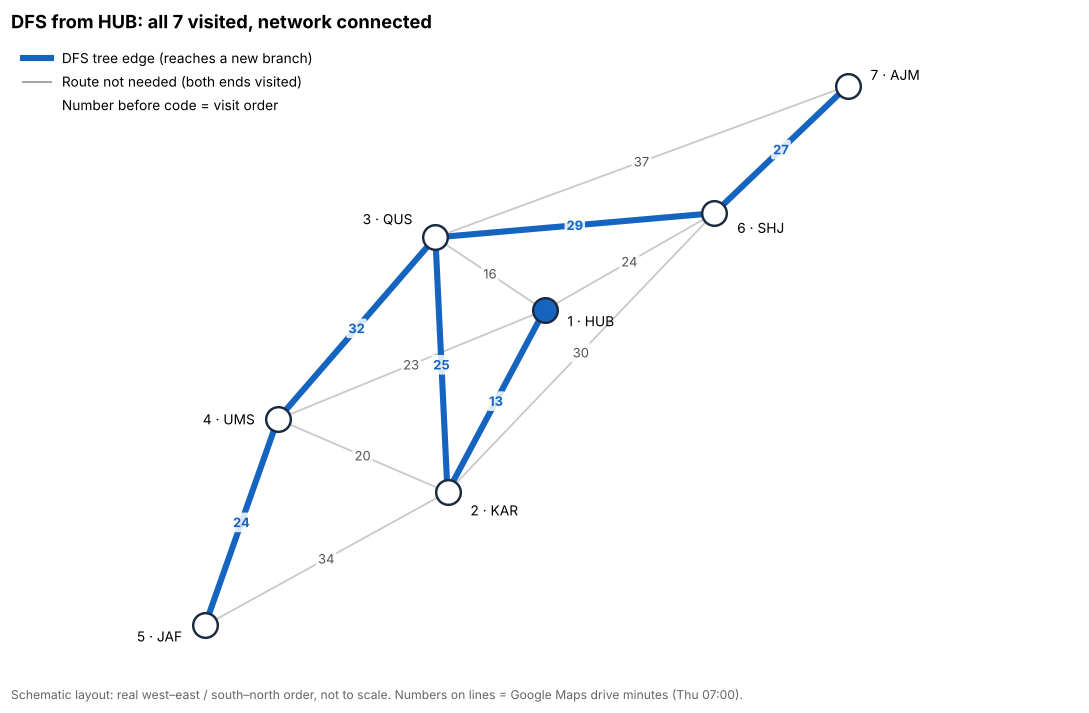

Tree edges: HUB-KAR, KAR-QUS, QUS-UMS, UMS-JAF, QUS-SHJ, SHJ-AJM (6 = 7 − 1)
Single point of failure (branch whose closure splits the network): none
Bridge routes (road whose loss splits the network): none
At X − 5 = 33: 11 routes, connected = True; Ajman's routes there: ['SHJ'] (single point of failure)


In [7]:
# Figure 2.1: DFS tree with visit order
num = {c: i + 1 for i, c in enumerate(dfs_order)}
fig, ax = plt.subplots(figsize=(10, 7))
draw_network(ax, "DFS from HUB: all 7 visited, network connected",
             edge_style={key(a, b): dict(color=BLUE, lw=4, alpha=1) for a, b in dfs_tree},
             node_colour={HUB: BLUE}, node_text={c: f"{num[c]} · {c}" for c in ORDER},
             legend=[("DFS tree edge (reaches a new branch)", BLUE, "-", 4), ("Route not needed (both ends visited)", GREY, "-", 1.2),
                     ("Number before code = visit order", "white", "-", 0)])
plt.tight_layout(); plt.show()

ap, brg = list(nx.articulation_points(G)), list(nx.bridges(G))
g33 = graph(routes_under(X - 5))
print("Tree edges:", ", ".join(f"{a}-{b}" for a, b in dfs_tree), f"({len(dfs_tree)} = 7 − 1)")
print("Single point of failure (branch whose closure splits the network):", ap or "none")
print("Bridge routes (road whose loss splits the network):", brg or "none")
print(f"At X − 5 = {X-5}: {g33.number_of_edges()} routes, connected = {nx.is_connected(g33)}; "
      f"Ajman's routes there: {sorted(g33.neighbors('AJM'))} (single point of failure)")

## 3 · Kruskal minimum network (Shashaank, Network Analyst)
Sort the 13 routes from shortest to longest. Accept a route unless both ends are already joined (it would close a loop). Stop when 6 = 7 − 1 routes are accepted; the rest are shown as rejected to explain why.

In [8]:
class DSU:
    def __init__(s, items): s.p = {i: i for i in items}
    def find(s, x):
        while s.p[x] != x: x = s.p[x]
        return x
    def union(s, a, b): s.p[s.find(b)] = s.find(a)

dsu, accepted, rows = DSU(ORDER), [], []
for a, b, m in ROUTES:                                   # already sorted by minutes, then matrix order
    ra, rb = dsu.find(a), dsu.find(b)
    if ra != rb:
        dsu.union(a, b); accepted.append((a, b, m)); decision = "ACCEPT"
        reason = f"joins two separate groups ({len(accepted)} of 6)"
    else:
        decision, reason = "REJECT", f"{a} and {b} already connected → would make a loop"
    groups = {}
    for c in ORDER: groups.setdefault(dsu.find(c), []).append(c)
    rows.append({"#": len(rows) + 1, "Route": f"{a}–{b}", "Minutes": m, "Decision": decision, "Why": reason,
                 "Groups after": "  ".join("{" + ",".join(g) + "}" for g in groups.values())})
KR = pd.DataFrame(rows).set_index("#")
mst_total, all_total = sum(m for *_, m in accepted), sum(m for *_, m in ROUTES)
prim = nx.minimum_spanning_tree(G, algorithm="prim")
print(f"Minimum network: {len(accepted)} routes, {mst_total} min  vs  all 13 routes {all_total} min  →  "
      f"{all_total - mst_total} min less ({(all_total - mst_total) / all_total:.1%}) summed route time")
print(f"Prim cross-check: {prim.size(weight='weight'):.0f} min · same routes: "
      f"{ {key(a, b) for a, b, _ in accepted} == {key(a, b) for a, b in prim.edges()} }")
KR

Minimum network: 6 routes, 124 min  vs  all 13 routes 334 min  →  210 min less (62.9%) summed route time
Prim cross-check: 124 min · same routes: True


,Route,Minutes,Decision,Why,Groups after
#,,,,,
1,HUB–KAR,13,ACCEPT,joins two separate groups (1 of 6),"{HUB,KAR} {QUS} {UMS} {JAF} {SHJ} {AJM}"
2,HUB–QUS,16,ACCEPT,joins two separate groups (2 of 6),"{HUB,KAR,QUS} {UMS} {JAF} {SHJ} {AJM}"
3,KAR–UMS,20,ACCEPT,joins two separate groups (3 of 6),"{HUB,KAR,QUS,UMS} {JAF} {SHJ} {AJM}"
4,HUB–UMS,23,REJECT,HUB and UMS already connected → would make a loop,"{HUB,KAR,QUS,UMS} {JAF} {SHJ} {AJM}"
5,HUB–SHJ,24,ACCEPT,joins two separate groups (4 of 6),"{HUB,KAR,QUS,UMS,SHJ} {JAF} {AJM}"
6,UMS–JAF,24,ACCEPT,joins two separate groups (5 of 6),"{HUB,KAR,QUS,UMS,JAF,SHJ} {AJM}"
7,KAR–QUS,25,REJECT,KAR and QUS already connected → would make a loop,"{HUB,KAR,QUS,UMS,JAF,SHJ} {AJM}"
8,SHJ–AJM,27,ACCEPT,joins two separate groups (6 of 6),"{HUB,KAR,QUS,UMS,JAF,SHJ,AJM}"
9,QUS–SHJ,29,REJECT,QUS and SHJ already connected → would make a loop,"{HUB,KAR,QUS,UMS,JAF,SHJ,AJM}"


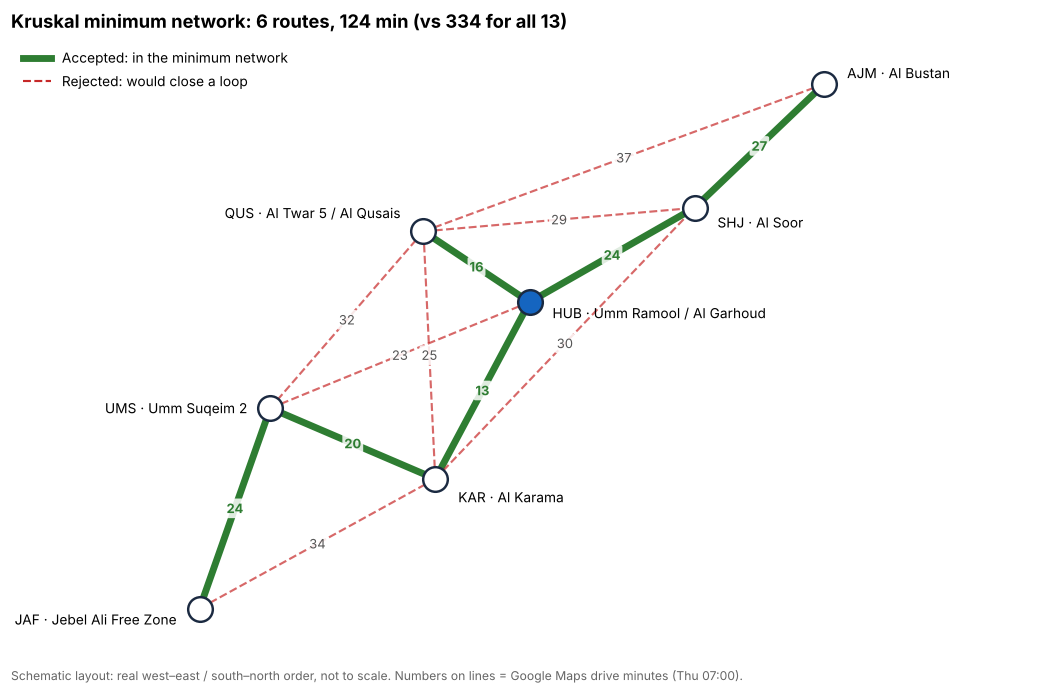

In [9]:
# Figure 3.1: minimum network vs rejected routes
fig, ax = plt.subplots(figsize=(10, 7))
style = {key(a, b): dict(color=RED, lw=1.4, ls="--", alpha=0.7) for a, b, _ in ROUTES}
style.update({key(a, b): dict(color=GREEN, lw=4.5, ls="-", alpha=1) for a, b, _ in accepted})
draw_network(ax, f"Kruskal minimum network: 6 routes, {mst_total} min (vs {all_total} for all 13)",
             edge_style=style, node_colour={HUB: BLUE},
             legend=[("Accepted: in the minimum network", GREEN, "-", 4.5), ("Rejected: would close a loop", RED, "--", 1.4)])
plt.tight_layout(); plt.show()

## 4 · Dijkstra service coverage (Siddal, Routing Analyst)
Fastest time from HUB to every branch over the 13 routes. Start HUB = 0, all others ∞. Each step settles the unsettled branch with the smallest time (ties: matrix order), then checks its routes: if going through it is **strictly** faster, update the time and where it came from. A branch meets the proposed internal transfer target when its time ≤ 20 min.

In [10]:
def dijkstra_trace(G, src):
    dist = {n: math.inf for n in ORDER}; prev = {n: None for n in ORDER}; ties = {n: [] for n in ORDER}
    dist[src] = 0; settled, rows = [], []
    f = lambda v: "∞" if v == math.inf else str(int(v))
    while len(settled) < len(ORDER):
        cand = [n for n in ORDER if n not in settled and dist[n] < math.inf]
        if not cand: break
        u = min(cand, key=lambda n: (dist[n], ORDER.index(n))); settled.append(u); notes = []
        for v in sorted(G.neighbors(u), key=ORDER.index):
            if v in settled: continue
            new = dist[u] + G[u][v]["weight"]
            if new < dist[v]:
                notes.append(f"{v}: {f(dist[v])}→{new} via {u}"); dist[v], prev[v], ties[v] = new, u, []
            elif new == dist[v]:
                notes.append(f"{v}: {new} via {u} = tie, keep via {prev[v]}"); ties[v].append(u)
            else:
                notes.append(f"{v}: {new} via {u}, no change")
        rows.append({"Step": len(settled), "Settle": f"{u} ({f(dist[u])})", "Routes checked": "; ".join(notes) or "no unsettled neighbours",
                     **{n: ("✔" if n in settled else "") + f(dist[n]) for n in ORDER if n != src}})
    return dist, prev, ties, pd.DataFrame(rows).set_index("Step")

def path(prev, n):
    p = []
    while n is not None: p.append(n); n = prev[n]
    return p[::-1]

dist, prev, ties, DJ = dijkstra_trace(G, HUB)
nxd = nx.single_source_dijkstra_path_length(G, HUB)
print("networkx cross-check, same times for every branch:", all(nxd[n] == dist[n] for n in ORDER))
DJ

networkx cross-check, same times for every branch: True


,Settle,Routes checked,KAR,QUS,UMS,JAF,SHJ,AJM
Step,,,,,,,,
1,HUB (0),KAR: ∞→13 via HUB; QUS: ∞→16 via HUB; UMS: ∞→23 via HUB; SHJ: ∞→24 via HUB,13,16,23,∞,24,∞
2,KAR (13),"QUS: 38 via KAR, no change; UMS: 33 via KAR, no change; JAF: ∞→47 via KAR; S...",✔13,16,23,47,24,∞
3,QUS (16),"UMS: 48 via QUS, no change; SHJ: 45 via QUS, no change; AJM: ∞→53 via QUS",✔13,✔16,23,47,24,53
4,UMS (23),"JAF: 47 via UMS = tie, keep via KAR",✔13,✔16,✔23,47,24,53
5,SHJ (24),AJM: 53→51 via SHJ,✔13,✔16,✔23,47,✔24,51
6,JAF (47),no unsettled neighbours,✔13,✔16,✔23,✔47,✔24,51
7,AJM (51),no unsettled neighbours,✔13,✔16,✔23,✔47,✔24,✔51


In [11]:
COV = pd.DataFrame([{
    "Code": n, "Area": AREA[n], "Fastest time (min)": int(dist[n]),
    "Route": " → ".join(path(prev, n)) + (f"  (tie: {' | '.join(' → '.join(path(prev, t) + [n]) for t in ties[n])})" if ties[n] else ""),
    "Direct Google drive (min)": T[key(HUB, n)],
    "Margin vs 20 min": TARGET - int(dist[n]),
    "Status": "WITHIN TARGET" if dist[n] <= TARGET else "OUTSIDE TARGET"} for n in ORDER if n != HUB]
).sort_values("Fastest time (min)").reset_index(drop=True)
print(f"At a {TARGET}-min target: {sum(COV.Status == 'WITHIN TARGET')} of 6 within (KAR, QUS); "
      f"{sum(COV.Status != 'WITHIN TARGET')} outside → upgrade candidates for Tab 3")
COV

At a 20-min target: 2 of 6 within (KAR, QUS); 4 outside → upgrade candidates for Tab 3


,Code,Area,Fastest time (min),Route,Direct Google drive (min),Margin vs 20 min,Status
0,KAR,Al Karama,13,HUB → KAR,13,7,WITHIN TARGET
1,QUS,Al Twar 5 / Al Qusais,16,HUB → QUS,16,4,WITHIN TARGET
2,UMS,Umm Suqeim 2,23,HUB → UMS,23,-3,OUTSIDE TARGET
3,SHJ,Al Soor,24,HUB → SHJ,24,-4,OUTSIDE TARGET
4,JAF,Jebel Ali Free Zone,47,HUB → KAR → JAF (tie: HUB → UMS → JAF),38,-27,OUTSIDE TARGET
5,AJM,Al Bustan,51,HUB → SHJ → AJM,38,-31,OUTSIDE TARGET


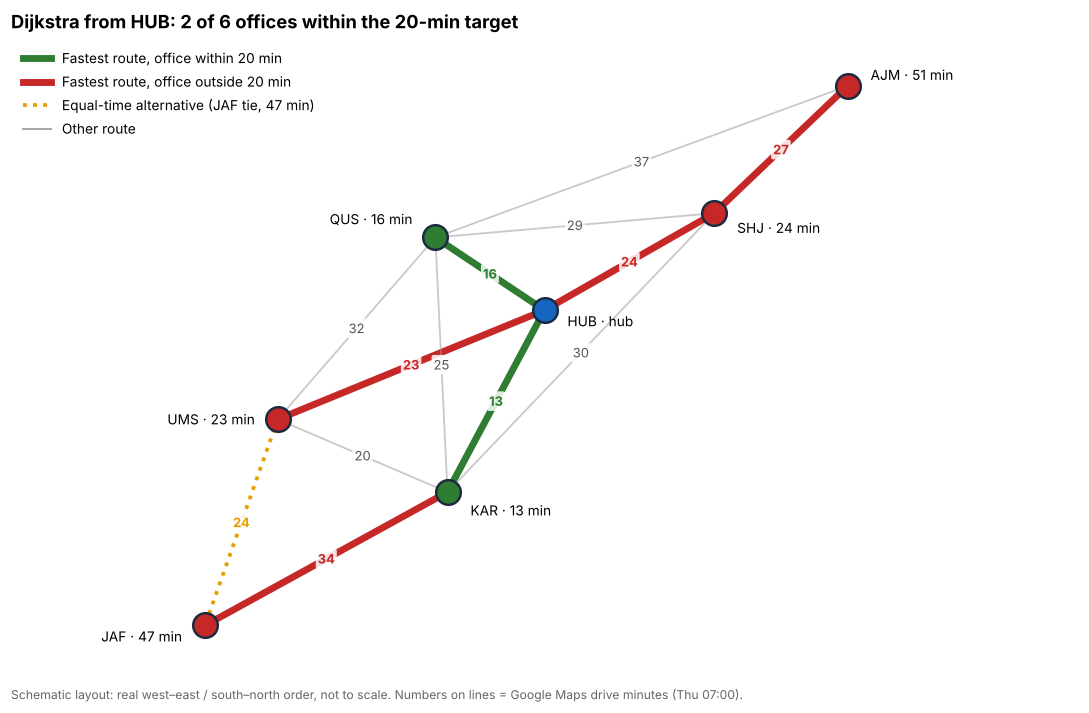

In [12]:
# Figure 4.1: shortest-path tree from HUB, coloured by target result
ok = {n: dist[n] <= TARGET for n in ORDER}
style = {key(prev[n], n): dict(color=GREEN if ok[n] else RED, lw=4.5, alpha=1) for n in ORDER if prev[n]}
for n in ORDER:
    for t in ties[n]:
        style[key(t, n)] = dict(color=AMBER, lw=2.5, ls=":", alpha=1)
fig, ax = plt.subplots(figsize=(10, 7))
draw_network(ax, f"Dijkstra from HUB: 2 of 6 offices within the {TARGET}-min target",
             edge_style=style,
             legend=[(f"Fastest route, office within {TARGET} min", GREEN, "-", 4.5), (f"Fastest route, office outside {TARGET} min", RED, "-", 4.5),
                     ("Equal-time alternative (JAF tie, 47 min)", AMBER, ":", 2.5), ("Other route", GREY, "-", 1.2)],
             node_colour={n: BLUE if n == HUB else (GREEN if ok[n] else RED) for n in ORDER},
             node_text={n: (f"{n} · hub" if n == HUB else f"{n} · {int(dist[n])} min") for n in ORDER})
plt.tight_layout(); plt.show()

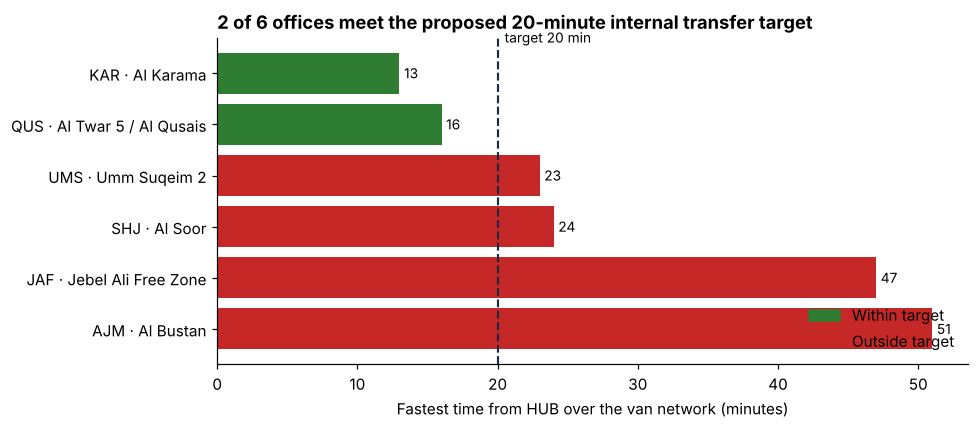

In [13]:
# Figure 4.2: travel time vs the 20-minute target
c = COV.sort_values("Fastest time (min)", ascending=False)
fig, ax = plt.subplots(figsize=(9, 4))
bars = ax.barh(c.Code + " · " + c.Area, c["Fastest time (min)"],
               color=[GREEN if s == "WITHIN TARGET" else RED for s in c.Status])
ax.bar_label(bars, padding=3, fontsize=9)
ax.axvline(TARGET, color=NAVY, ls="--", lw=1.4); ax.text(TARGET + 0.5, len(c) - 0.4, f"target {TARGET} min", fontsize=9)
ax.set_xlabel("Fastest time from HUB over the van network (minutes)")
ax.set_title("2 of 6 offices meet the proposed 20-minute internal transfer target", loc="left")
ax.legend(handles=[plt.Rectangle((0, 0), 1, 1, color=GREEN), plt.Rectangle((0, 0), 1, 1, color=RED)],
          labels=["Within target", "Outside target"], frameon=False, loc="lower right")
plt.tight_layout(); plt.show()

In [14]:
# Figure 4.3: which offices pass at each target (the slider, as a table)
grid = pd.DataFrame({t: ["✓" if dist[n] <= t else "✗" for n in COV.Code] for t in [15, 16, 20, 22, 23, 24, 47, 51]},
                    index=COV.Code + " (" + COV["Fastest time (min)"].astype(str) + " min)")
grid.columns = [f"{t} min" for t in grid.columns]
print("Same 2 offices pass for every target from 16 to 22 min; UMS flips at 23, SHJ at 24.")
grid

Same 2 offices pass for every target from 16 to 22 min; UMS flips at 23, SHJ at 24.


,15 min,16 min,20 min,22 min,23 min,24 min,47 min,51 min
KAR (13 min),✓,✓,✓,✓,✓,✓,✓,✓
QUS (16 min),✗,✓,✓,✓,✓,✓,✓,✓
UMS (23 min),✗,✗,✗,✗,✓,✓,✓,✓
SHJ (24 min),✗,✗,✗,✗,✗,✓,✓,✓
JAF (47 min),✗,✗,✗,✗,✗,✗,✓,✓
AJM (51 min),✗,✗,✗,✗,✗,✗,✗,✓


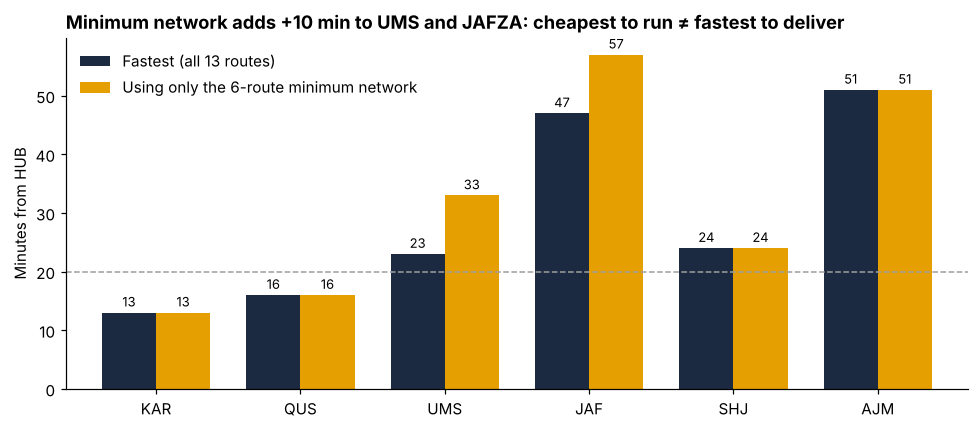

,Fastest (all 13 routes),Using only the 6-route minimum network,Extra minutes
KAR,13,13,0
QUS,16,16,0
UMS,23,33,10
JAF,47,57,10
SHJ,24,24,0
AJM,51,51,0


In [15]:
# Figure 4.4: why the minimum network (Tab 1) is not the fastest delivery network (Tab 2)
T_mst = nx.single_source_dijkstra_path_length(graph(accepted), HUB)
cmp = pd.DataFrame({"Fastest (all 13 routes)": [dist[n] for n in ORDER[1:]],
                    "Using only the 6-route minimum network": [T_mst[n] for n in ORDER[1:]]}, index=ORDER[1:])
ax = cmp.plot.bar(figsize=(9, 4), color=[NAVY, AMBER], width=0.75, rot=0)
for cont in ax.containers: ax.bar_label(cont, fmt="%d", fontsize=8.5, padding=2)
ax.axhline(TARGET, color=GREY, ls="--", lw=1); ax.set_ylabel("Minutes from HUB")
ax.set_title("Minimum network adds +10 min to UMS and JAFZA: cheapest to run ≠ fastest to deliver", loc="left")
ax.legend(frameon=False); plt.tight_layout(); plt.show()
cmp.assign(**{"Extra minutes": cmp.iloc[:, 1] - cmp.iloc[:, 0]})

## 5 · Investment: 0/1 knapsack by dynamic programming vs greedy (Joan, Investment Analyst)
Four offices miss the 20-minute target, each with one priced upgrade. Budget AED 450,000 cannot fund all four (AED 481,860).
The grid follows Joan's hand-trace convention: costs rounded to the nearest **AED 10,000** (46 columns, budget w = 0…45), benefits in **AED '000 per year**. An exact-AED check follows the grid.

Cell rule: `K[i][w] = K[i-1][w]` if cost_i > w, else `max(K[i-1][w], benefit_i + K[i-1][w − cost_i])`.

In [16]:
U = upgrades.set_index("Code").loc[["UMS", "JAF", "SHJ", "AJM"]].reset_index()
U["Cost (AED 10k units)"] = (U.Cost_AED / 10_000).round().astype(int)
U["Benefit (AED '000/yr)"] = (U.Benefit_AED / 1000).astype(int)
U["Benefit per AED"] = (U.Benefit_AED / U.Cost_AED).round(2)
names, costs, bens = U.Code.tolist(), U["Cost (AED 10k units)"].tolist(), U["Benefit (AED '000/yr)"].tolist()
W = BUDGET // 10_000
n = len(costs)
K = [[0] * (W + 1) for _ in range(n + 1)]
for i in range(1, n + 1):
    for w in range(W + 1):
        K[i][w] = K[i - 1][w] if costs[i - 1] > w else max(K[i - 1][w], bens[i - 1] + K[i - 1][w - costs[i - 1]])
# traceback
chosen, w, trace_cells, tb = [], W, set(), []
for i in range(n, 0, -1):
    trace_cells.add((i, w)); took = K[i][w] != K[i - 1][w]
    tb.append({"Row": f"{i} {names[i-1]}", "Cell": f"K[{i}][{w}] = {K[i][w]}", "Above": f"K[{i-1}][{w}] = {K[i-1][w]}",
               "Decision": f"TAKE → move left {costs[i-1]} to w = {w - costs[i-1]}" if took else "LEAVE → go up"})
    if took: chosen.append(names[i - 1]); w -= costs[i - 1]
trace_cells.add((0, w)); chosen.reverse()
print(f"K[{n}][{W}] = {K[n][W]} → DP funds {', '.join(chosen)}")
U[["Code", "Upgrade", "Cost_AED", "Cost (AED 10k units)", "Benefit_AED", "Benefit (AED '000/yr)", "Benefit per AED"]]

K[4][45] = 765 → DP funds JAF, SHJ, AJM


,Code,Upgrade,Cost_AED,Cost (AED 10k units),Benefit_AED,Benefit (AED '000/yr),Benefit per AED
0,UMS,Express motorbike courier,69900,7,135000,135,1.93
1,JAF,JAFZA mini-hub,143520,14,360000,360,2.51
2,SHJ,Sharjah mini-hub,130920,13,225000,225,1.72
3,AJM,Ajman mini-hub,137520,14,180000,180,1.31


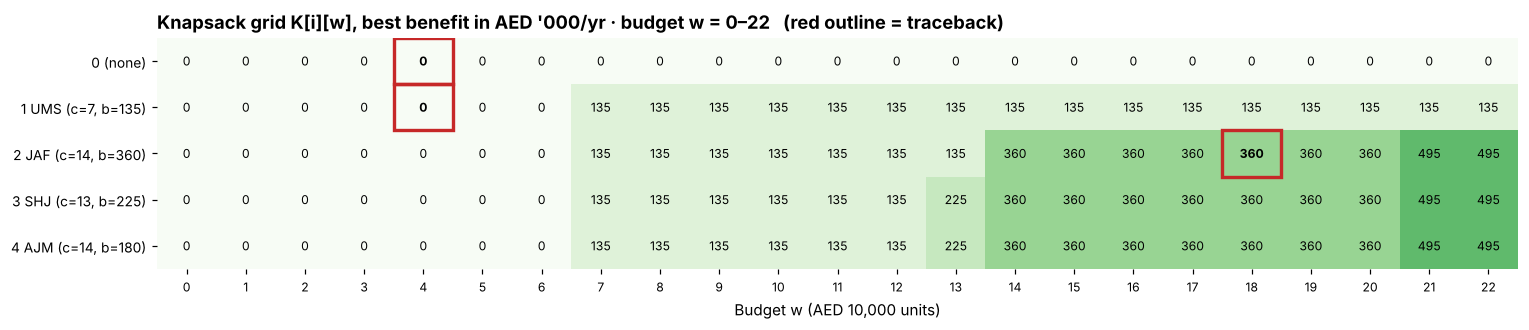

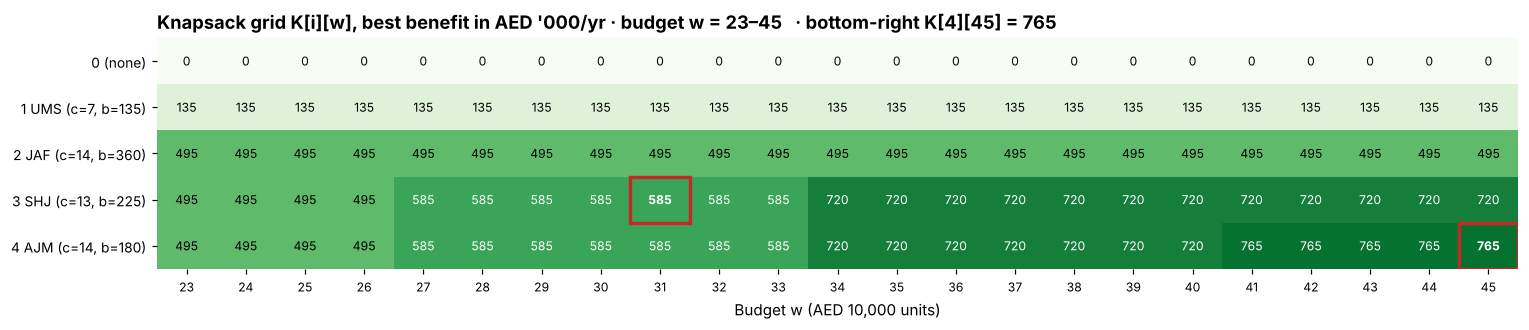

,Row,Cell,Above,Decision
0,4 AJM,K[4][45] = 765,K[3][45] = 720,TAKE → move left 14 to w = 31
1,3 SHJ,K[3][31] = 585,K[2][31] = 495,TAKE → move left 13 to w = 18
2,2 JAF,K[2][18] = 360,K[1][18] = 135,TAKE → move left 14 to w = 4
3,1 UMS,K[1][4] = 0,K[0][4] = 0,LEAVE → go up


In [17]:
# Figure 5.1: the knapsack grid (two halves so it stays readable); outlined = traceback path
rowlab = ["0 (none)"] + [f"{i+1} {names[i]} (c={costs[i]}, b={bens[i]})" for i in range(n)]
for lo, hi in [(0, 23), (23, 46)]:
    fig, ax = plt.subplots(figsize=(14, 3.1))
    sub = [r[lo:hi] for r in K]
    ax.imshow(sub, cmap="Greens", vmin=0, vmax=900, aspect="auto")
    for i in range(n + 1):
        for j, w in enumerate(range(lo, hi)):
            ax.text(j, i, K[i][w], ha="center", va="center", fontsize=8,
                    color="white" if K[i][w] > 560 else "black", fontweight="bold" if (i, w) in trace_cells else "normal")
            if (i, w) in trace_cells:
                ax.add_patch(Rectangle((j - .5, i - .5), 1, 1, fill=False, ec=RED, lw=2.2))
    ax.set_xticks(range(hi - lo), range(lo, hi), fontsize=8); ax.set_yticks(range(n + 1), rowlab, fontsize=9)
    ax.set_xlabel("Budget w (AED 10,000 units)")
    ax.set_title(f"Knapsack grid K[i][w], best benefit in AED '000/yr · budget w = {lo}–{hi-1}"
                 + ("   (red outline = traceback)" if lo == 0 else f"   · bottom-right K[4][45] = {K[n][W]}"), loc="left")
    ax.spines[:].set_visible(False); plt.tight_layout(); plt.show()
pd.DataFrame(tb)

In [18]:
# Greedy (best benefit per AED first) vs DP, in exact AED, plus brute force over all 16 combinations
def greedy_exact(budget):
    left, picks, steps = budget, [], []
    for r in U.sort_values("Benefit per AED", ascending=False).itertuples():
        fits = r.Cost_AED <= left
        if fits: left -= r.Cost_AED; picks.append(r.Code)
        steps.append({"Order": len(steps) + 1, "Upgrade": r.Code, "Benefit per AED": round(r.Benefit_AED / r.Cost_AED, 2),
                      "Cost (AED)": f"{r.Cost_AED:,}", "Fits?": "yes → take" if fits else "no → skip", "Left after (AED)": f"{left:,}"})
    return picks, steps

def best_exact(budget):
    best = (0, ())
    for k in range(5):
        for combo in itertools.combinations(range(4), k):
            c = sum(U.Cost_AED[i] for i in combo)
            if c <= budget:
                b = sum(U.Benefit_AED[i] for i in combo)
                best = max(best, (b, combo))
    return best[0], [U.Code[i] for i in best[1]]

g_picks, g_steps = greedy_exact(BUDGET)
dp_b, dp_picks = best_exact(BUDGET)
cost_of = lambda ps: int(U.set_index("Code").loc[ps, "Cost_AED"].sum())
ben_of = lambda ps: int(U.set_index("Code").loc[ps, "Benefit_AED"].sum())
print(f"DP (exact AED):  {', '.join(dp_picks)} · cost AED {cost_of(dp_picks):,} · benefit AED {dp_b:,}/yr · "
      f"same choice as the AED 10k grid: {sorted(dp_picks) == sorted(chosen)}")
print(f"Greedy:          {', '.join(g_picks)} · cost AED {cost_of(g_picks):,} · benefit AED {ben_of(g_picks):,}/yr")
print(f"DP beats greedy by AED {dp_b - ben_of(g_picks):,} a year at AED {BUDGET:,}")
pd.DataFrame(g_steps).set_index("Order")

DP (exact AED):  JAF, SHJ, AJM · cost AED 411,960 · benefit AED 765,000/yr · same choice as the AED 10k grid: True
Greedy:          JAF, UMS, SHJ · cost AED 344,340 · benefit AED 720,000/yr
DP beats greedy by AED 45,000 a year at AED 450,000


,Upgrade,Benefit per AED,Cost (AED),Fits?,Left after (AED)
Order,,,,,
1,JAF,2.51,"143,520",yes → take,"306,480"
2,UMS,1.93,"69,900",yes → take,"236,580"
3,SHJ,1.72,"130,920",yes → take,"105,660"
4,AJM,1.31,"137,520",no → skip,"105,660"


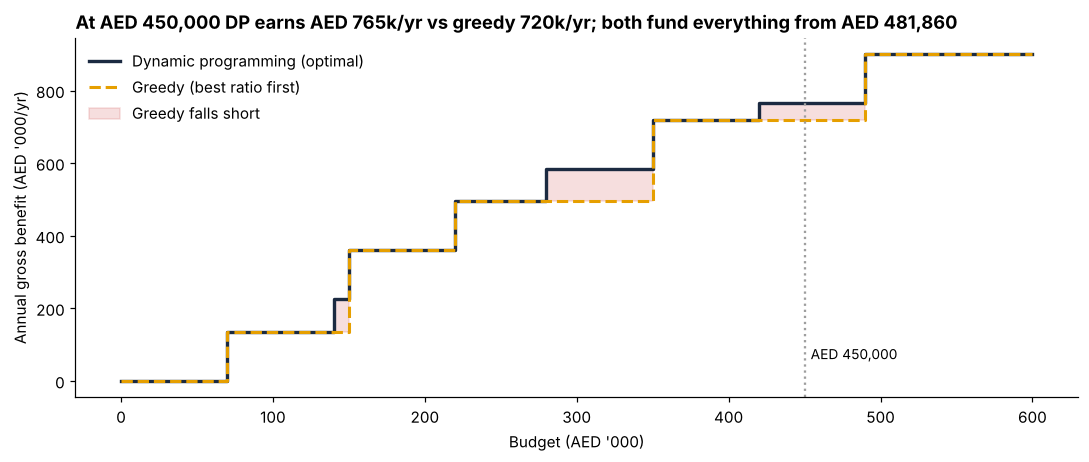

Budgets where greedy is beaten (AED): 140,000–140,000, 280,000–340,000, 420,000–480,000


In [19]:
# Figure 5.2: DP vs greedy at every budget (exact AED, AED 10,000 steps)
budgets = list(range(0, 600_001, 10_000))
sweep = pd.DataFrame({"Budget": budgets,
                      "DP optimum": [best_exact(b)[0] for b in budgets],
                      "Greedy": [ben_of(greedy_exact(b)[0]) if greedy_exact(b)[0] else 0 for b in budgets]})
sweep["Gap"] = sweep["DP optimum"] - sweep["Greedy"]
fig, ax = plt.subplots(figsize=(10, 4.3))
ax.step(sweep.Budget / 1000, sweep["DP optimum"] / 1000, where="post", color=NAVY, lw=2.2, label="Dynamic programming (optimal)")
ax.step(sweep.Budget / 1000, sweep["Greedy"] / 1000, where="post", color=AMBER, lw=2, ls="--", label="Greedy (best ratio first)")
gap = sweep[sweep.Gap > 0]
ax.fill_between(sweep.Budget / 1000, sweep.Greedy / 1000, sweep["DP optimum"] / 1000, step="post", color=RED, alpha=0.15,
                label="Greedy falls short")
ax.axvline(BUDGET / 1000, color=GREY, ls=":"); ax.text(BUDGET / 1000 + 4, 60, f"AED {BUDGET:,}", fontsize=9)
ax.set_xlabel("Budget (AED '000)"); ax.set_ylabel("Annual gross benefit (AED '000/yr)")
ax.set_title("At AED 450,000 DP earns AED 765k/yr vs greedy 720k/yr; both fund everything from AED 481,860", loc="left")
ax.legend(frameon=False, loc="upper left"); plt.tight_layout(); plt.show()
print("Budgets where greedy is beaten (AED):",
      ", ".join(f"{a:,}–{b:,}" for a, b in [(g.Budget.min(), g.Budget.max()) for _, g in gap.groupby((gap.Budget.diff() != 10_000).cumsum())]))

## 6 · Summary: notebook vs dashboard (baseline X 38, HUB, 20 min, AED 450,000)
Each *Notebook* value below is computed in this notebook. The *Dashboard v2.3* column is **recomputed at run time from the
project's own code** (`../src`: the same functions the Streamlit app calls for its fixed baseline evidence run), and the
*Status* column is calculated by comparing the two — `MATCH` or `MISMATCH`, never typed. (The original notebook compared
itself with a typed copy of the v2.1 dashboard values.)

In [20]:
# v2.3: the dashboard side is recomputed from the project's own code — nothing below is typed by hand
import sys
sys.path.insert(0, str(Path("..").resolve()))
from src.data_loader import load_dataset
from src.working_tab import baseline_run
from src.notebook_diagrams import live_baseline_values

_ds = load_dataset()
_sc, _pool, _inv, _trace = baseline_run(_ds)
dashboard = live_baseline_values(_sc, _inv, _trace)          # X 38 · HUB · 20 min · AED 450,000 (v2.3 code)

got = {"Routes under X = 38": len(ROUTES), "DFS visit order": " → ".join(dfs_order), "Connected": nx.is_connected(G),
       "Kruskal total (min)": mst_total, "All-routes total (min)": all_total, "Kruskal routes": len(accepted),
       "Dijkstra KAR/QUS/UMS/SHJ/JAF/AJM": "/".join(str(int(dist[c])) for c in ["KAR", "QUS", "UMS", "SHJ", "JAF", "AJM"]),
       "Within 20-min target": ", ".join(COV.loc[COV.Status == "WITHIN TARGET", "Code"]),
       "Knapsack K[4][45]": K[n][W], "DP choice": ", ".join(dp_picks), "Greedy choice": ", ".join(g_picks),
       "DP − greedy (AED/yr)": dp_b - ben_of(g_picks)}
status = {k: "MATCH" if str(got[k]) == str(dashboard.get(k)) else "MISMATCH" for k in got}
print(f"{sum(s == 'MATCH' for s in status.values())} of {len(status)} values match the v2.3 dashboard code")
pd.DataFrame({"Notebook": {k: str(v) for k, v in got.items()},
              "Dashboard v2.3 (computed now)": {k: dashboard.get(k, "—") for k in got}, "Status": status})

12 of 12 values match the v2.3 dashboard code


,Notebook,Dashboard v2.3 (computed now),Status
Routes under X = 38,13,13,MATCH
DFS visit order,HUB → KAR → QUS → UMS → JAF → SHJ → AJM,HUB → KAR → QUS → UMS → JAF → SHJ → AJM,MATCH
Connected,True,True,MATCH
Kruskal total (min),124,124,MATCH
All-routes total (min),334,334,MATCH
Kruskal routes,6,6,MATCH
Dijkstra KAR/QUS/UMS/SHJ/JAF/AJM,13/16/23/24/47/51,13/16/23/24/47/51,MATCH
Within 20-min target,"KAR, QUS","KAR, QUS",MATCH
Knapsack K[4][45],765,765,MATCH
DP choice,"JAF, SHJ, AJM","JAF, SHJ, AJM",MATCH


### Service disposition (dashboard v2.3 classifier, baseline DP and greedy portfolios)
The dashboard separates four service dispositions: **DIRECT HUB TRANSFER WITHIN TARGET** (road-network shortest time
≤ target), **ALTERNATIVE MODE WITHIN TARGET (ASSUMPTION)** (a selected option whose stated mode time is ≤ target, e.g.
the UMS motorbike at an assumed 18 min from HUB), **LOCAL FULFILMENT UPGRADE** (a selected mini-hub — the hub-to-branch
road time is unchanged; it is not a zero-minute journey and not direct-transfer compliance) and
**OUTSIDE SELECTED SERVICE PLAN**. The table below is computed by the dashboard's classifier (`src/investment_core.py`), not by this notebook.

In [21]:
from src import investment_core as ic
_rows = []
for _label, _plan in [("DP", _inv["dp"]["plan"]), ("Greedy", _inv["greedy"]["plan"])]:
    for _r in _plan["rows"]:
        _rows.append({"Portfolio": _label, "Branch": _r["branch_code"], "Shortest hub time (min)": _r["shortest_hub_time_min"],
                      "Selected upgrade": _r["selected_intervention"], "Primary disposition": _r["modelled_service_disposition"]})
    print(f"{_label}: {ic.plan_summary(_plan)}")
pd.DataFrame(_rows)

DP: 2 direct hub transfer · 3 local fulfilment · 1 outside plan (UMS)
Greedy: 2 direct hub transfer · 1 alternative mode (assumption) · 2 local fulfilment · 1 outside plan (AJM)


,Portfolio,Branch,Shortest hub time (min),Selected upgrade,Primary disposition
0,DP,KAR,13,—,DIRECT HUB TRANSFER WITHIN TARGET
1,DP,QUS,16,—,DIRECT HUB TRANSFER WITHIN TARGET
2,DP,UMS,23,—,OUTSIDE SELECTED SERVICE PLAN
3,DP,JAF,47,JAFZA mini-hub — local fulfilment,LOCAL FULFILMENT UPGRADE
4,DP,SHJ,24,Sharjah mini-hub — local fulfilment,LOCAL FULFILMENT UPGRADE
5,DP,AJM,51,Ajman mini-hub — local fulfilment,LOCAL FULFILMENT UPGRADE
6,Greedy,KAR,13,—,DIRECT HUB TRANSFER WITHIN TARGET
7,Greedy,QUS,16,—,DIRECT HUB TRANSFER WITHIN TARGET
8,Greedy,UMS,23,"Express motorbike courier — alternative mode, 18 min (assumption)",ALTERNATIVE MODE WITHIN TARGET (ASSUMPTION)
9,Greedy,JAF,47,JAFZA mini-hub — local fulfilment,LOCAL FULFILMENT UPGRADE
